# 04 — Kết quả huấn luyện 4 client (2 client mỗi nguồn)

Notebook đọc **trực tiếp các file kết quả tải từ Modal** (`results_modal_multidataset/{run_id}/`) và vẽ lại:

1. Phân bố dữ liệu của 4 client
2. Learning curve của FL theo vòng (validation, train loss)
3. F1 validation của từng client theo vòng
4. Learning curve của baseline (local-only, centralized) theo epoch
5. So sánh trên tập test: 4 client với 2 client
6. Ma trận nhầm lẫn
7. **Dashboard tổng hợp** (một hình duy nhất, lưu ra PNG để đưa vào báo cáo hoặc slide)

Mọi con số đều lấy từ CSV mà pipeline ghi ra trong lúc train (`*_rounds.csv`, `*_clients.csv`,
`*_epochs.csv`, `evaluation_by_dataset.csv`, `confusion.csv`). Notebook không train lại gì.
Mỗi cấu hình chỉ chạy **1 seed**, nên chênh lệch nhỏ giữa các phương pháp chưa đủ để kết luận.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "multidataset.json").exists():  # chạy được từ notebooks/ hoặc gốc dự án
    ROOT = ROOT.parent
RES = ROOT / "results_modal_multidataset"

RUN_4C = "20261122_152058_5ec64a"        # FL DAS / all / FedProx + local-only, 4 client
RUN_2C = "20261109_161229_a7ff36"        # FL DAS / all + centralized + local, 2 client
RUN_2C_PROX = "20261109_193340_f712a4"   # FedProx, 2 client
DATA_4C = ROOT / "data_paper_multi_4c" / "main"
SOURCES = {"cicddos2019": "CICDDoS2019", "unsw_nb15": "UNSW-NB15"}
CLASSES = ["BENIGN", "DOS_DDOS", "OTHER_ATTACK"]


def find_central_4c():
    """Run centralized dùng cùng bundle dữ liệu 4 client; None nếu chưa có (job chưa xong/chưa tải)."""
    bundle = json.loads((RES / RUN_4C / "status_snapshot.json").read_text(encoding="utf-8"))["bundle_id"]
    for d in sorted(RES.iterdir(), reverse=True):
        snap = d / "status_snapshot.json"
        if d.name == RUN_4C or not snap.exists():
            continue
        if json.loads(snap.read_text(encoding="utf-8")).get("bundle_id") != bundle:
            continue
        if list((d / "main" / "das" / "baselines").glob("centralized_*_epochs.csv")):
            return d.name
    return None


RUN_CENTRAL_4C = find_central_4c()
print("Run 4 client       :", RUN_4C)
print("Run centralized 4c :", RUN_CENTRAL_4C or "chưa có — các ô centralized sẽ bỏ qua")
print("Run 2 client       :", RUN_2C, "+", RUN_2C_PROX)

Run 4 client       : 20261122_152058_5ec64a
Run centralized 4c : 20261122_235344_298853
Run 2 client       : 20261109_161229_a7ff36 + 20261109_193340_f712a4


### Bảng màu và kiểu vẽ

Mỗi phương pháp giữ **một màu cố định** ở mọi biểu đồ (màu đi theo phương pháp, không theo thứ hạng),
để người xem nhận ra ngay khi chuyển hình. Đường mảnh, lưới nhạt, mỗi biểu đồ chỉ có một trục y.

In [2]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.edgecolor": "#8a8985", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False, "lines.linewidth": 2,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
COLOR = {  # bảng màu phân loại cố định (thứ tự slot 1..8)
    "FL DAS": "#2a78d6", "FL all": "#eb6834", "FedProx": "#1baf7a", "Centralized": "#6250d6",
    "Local": "#eda100",
    "C1": "#2a78d6", "C2": "#eb6834", "C3": "#1baf7a", "C4": "#eda100",
    "2 client": "#8a8985", "4 client": "#2a78d6",
}


def short(method: str) -> str:
    """Tên phương pháp gọn cho biểu đồ."""
    if method.startswith("FL FedProx"):
        return "FedProx"
    if method.startswith("FL") and "all" in method:
        return "FL all"
    if method.startswith("FL"):
        return "FL DAS"
    if method.startswith("Centralized"):
        return "Centralized"
    m = re.match(r"Local-only\[(\w+)(?: #(\d))?\]", method)
    if m:
        src = "CIC" if m.group(1) == "cicddos2019" else "UNSW"
        return f"Local C{m.group(2)} ({src})" if m.group(2) else f"Local {src}"
    return method


def read_eval(run, variant="das"):
    f = RES / run / "main" / variant / "evaluation_by_dataset.csv"
    return pd.read_csv(f) if f.exists() else pd.DataFrame()


def rounds(run, variant="das", prox=False):
    fl = RES / run / "main" / variant / "fl"
    pat = "*_fedprox_*_rounds.csv" if prox else "*_seed0_rounds.csv"
    return pd.read_csv(next(fl.glob(pat)))

## 1. Phân bố dữ liệu của 4 client

Mỗi dataset được chia **đều 50/50** cho 2 client, phân tầng theo nhãn gốc, nên 2 client cùng nguồn
có tỉ lệ lớp gần như giống hệt nhau. Khác biệt lớn nằm **giữa hai nguồn**: CIC không có lớp
OTHER_ATTACK, còn UNSW có ít DoS. Đây là dữ liệu non-IID ở mức nguồn.

label,BENIGN,DOS_DDOS,OTHER_ATTACK,Tổng
C1 · CIC,11715,38285,0,50000
C2 · CIC,11715,38285,0,50000
C3 · UNSW,17051,4906,28043,50000
C4 · UNSW,17051,4905,28044,50000


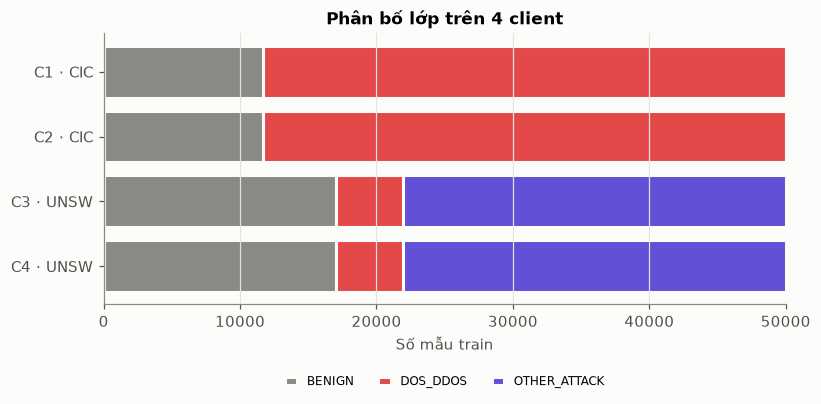

In [3]:
counts = {}
for k in range(1, 5):
    tr = pd.read_parquet(DATA_4C / "multidataset" / f"client_{k}.parquet", columns=["label"])
    counts[f"C{k}"] = tr["label"].value_counts().reindex(CLASSES, fill_value=0)
dist = pd.DataFrame(counts).T
manifest = json.loads((DATA_4C / "dataset_manifest.json").read_text(encoding="utf-8"))
src_of = {f"C{c['client']}": SOURCES[c["dataset_id"]] for c in manifest["clients"]}
dist.index = [f"{k} · {'CIC' if src_of[k].startswith('CIC') else 'UNSW'}" for k in dist.index]
display(dist.assign(Tổng=dist.sum(axis=1)))

cls_color = {"BENIGN": "#8a8985", "DOS_DDOS": "#e34948", "OTHER_ATTACK": "#6250d6"}


def plot_distribution(ax):
    left = np.zeros(len(dist))
    for c in CLASSES:
        ax.barh(dist.index, dist[c], left=left, color=cls_color[c], label=c, edgecolor="#fcfcfb", linewidth=2)
        left += dist[c].values
    ax.invert_yaxis()
    ax.set_xlabel("Số mẫu train")
    ax.set_title("Phân bố lớp trên 4 client")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8, handlelength=1)
    ax.grid(axis="y", visible=False)


fig, ax = plt.subplots(figsize=(8, 3.2))
plot_distribution(ax)
plt.show()

## 2. Learning curve của FL theo vòng

**Điểm validation** dùng để chọn mô hình = trung bình theo nguồn của F1-macro-present
(mỗi nguồn nặng như nhau). Đường xám nét đứt là FL DAS của run **2 client** cũ, để so sánh.
Dấu chấm tròn đánh dấu vòng được chọn làm *best* (validation cao nhất).

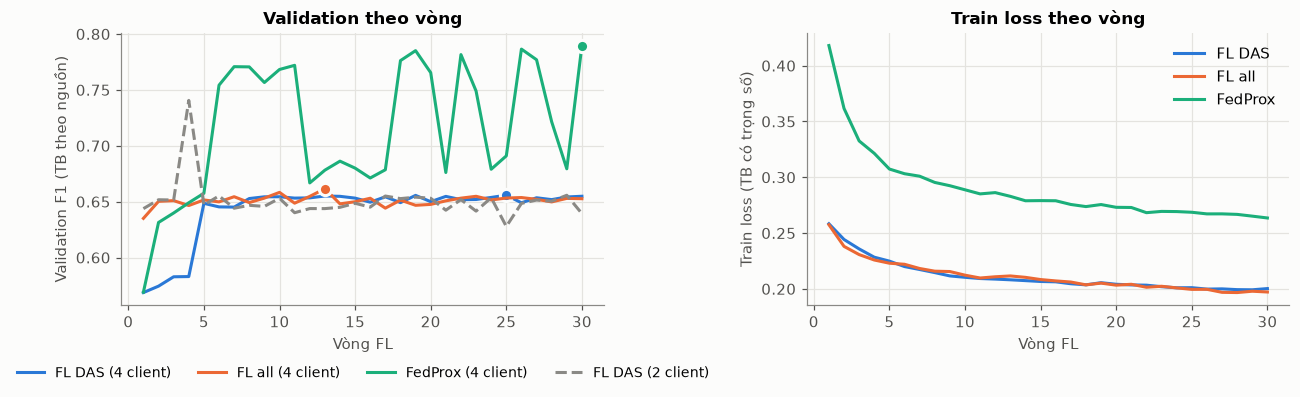

,best_round,best_val,val_vòng_30,comm_MB_30_vòng
FL DAS,25.0,0.6558,0.6549,155.4230
FL all,13.0,0.6616,0.6526,155.7302
FedProx,30.0,0.7897,0.7897,155.4230


In [4]:
curves = {
    "FL DAS": rounds(RUN_4C, "das"),
    "FL all": rounds(RUN_4C, "all"),
    "FedProx": rounds(RUN_4C, "das", prox=True),
}
ref_2c = rounds(RUN_2C, "das")


def plot_fl_val(ax):
    for name, r in curves.items():
        ax.plot(r["round"], r["val_score"], color=COLOR[name], label=f"{name} (4 client)")
        b = r.loc[r["val_score"].idxmax()]
        ax.plot(b["round"], b["val_score"], "o", ms=8, color=COLOR[name], mec="#fcfcfb", mew=2)
    ax.plot(ref_2c["round"], ref_2c["val_score"], "--", color=COLOR["2 client"], label="FL DAS (2 client)")
    ax.set_xlabel("Vòng FL")
    ax.set_ylabel("Validation F1 (TB theo nguồn)")
    ax.set_title("Validation theo vòng")
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=9)


def plot_fl_loss(ax):
    for name, r in curves.items():
        ax.plot(r["round"], r["train_loss"], color=COLOR[name], label=name)
    ax.set_xlabel("Vòng FL")
    ax.set_ylabel("Train loss (TB có trọng số)")
    ax.set_title("Train loss theo vòng")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_fl_val(axes[0])
plot_fl_loss(axes[1])
plt.tight_layout()
plt.show()
pd.DataFrame({n: {"best_round": int(r.loc[r.val_score.idxmax(), "round"]), "best_val": r.val_score.max(),
                  "val_vòng_30": r.val_score.iloc[-1], "comm_MB_30_vòng": r.comm_MB.iloc[-1]}
              for n, r in curves.items()}).T.round(4)

**Đọc biểu đồ:** train loss của cả ba phương pháp giảm đều, nghĩa là các client vẫn học tốt trên dữ liệu
của mình. Đường validation thì dao động và không tăng theo loss, vì mô hình chung khó vừa khớp CIC
vừa khớp UNSW (xem phần 3). Đường FedProx dao động mạnh giữa các vòng và đạt đỉnh ở vòng 30, nên 30 vòng có thể chưa đủ để hội tụ. `comm_MB` của 4 client gấp đôi 2 client, vì mỗi vòng có 4 client gửi và nhận trọng số.

## 3. F1 validation của từng client theo vòng (FL DAS)

Mô hình chung sau mỗi vòng được gửi về và đánh giá trên **validation riêng** của từng client.

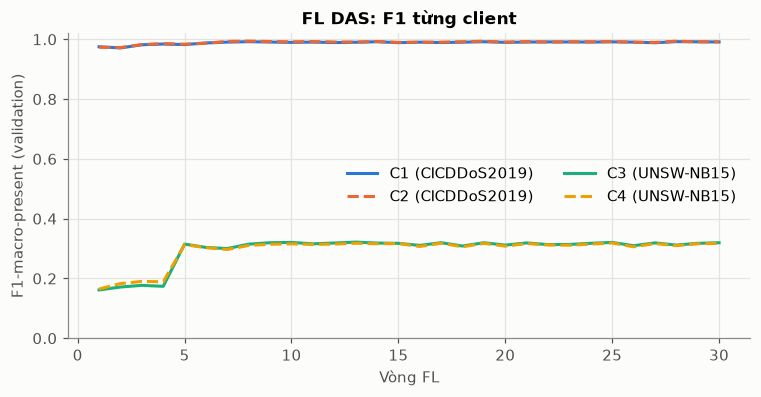

In [5]:
def plot_per_client(ax, r=curves["FL DAS"]):
    style = {0: "-", 1: "--", 2: "-", 3: "--"}
    for pid in range(4):
        k = f"C{pid + 1}"
        ax.plot(r["round"], r[f"val_f1mp_pid{pid}"], style[pid], color=COLOR[k],
                label=f"{k} ({src_of[k]})")
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Vòng FL")
    ax.set_ylabel("F1-macro-present (validation)")
    ax.set_title("FL DAS: F1 từng client")
    ax.legend(ncol=2, loc="center right")


fig, ax = plt.subplots(figsize=(8, 3.6))
plot_per_client(ax)
plt.show()

**Khoảng cách giữa hai nguồn là điểm chính cần phân tích:** 2 client CIC đạt F1 khoảng 0,98, còn 2 client UNSW
chỉ khoảng 0,3 (FL DAS). Hai client cùng nguồn gần như trùng nhau, vì dữ liệu chia đều nên chúng thấy cùng một phân bố.
Vì vậy tăng từ 2 lên 4 client **không thêm đa dạng dữ liệu**, mà chỉ chia nhỏ dữ liệu của mỗi nguồn.

## 4. Learning curve của baseline theo epoch

- **Local-only:** mỗi client tự train trên 50k mẫu của mình, không chia sẻ gì.
- **Centralized:** gộp dữ liệu của cả 4 client lại (cận tham chiếu, không phải FL).

Trục x là epoch (150 epoch = 30 vòng × 5 epoch cục bộ của FL).

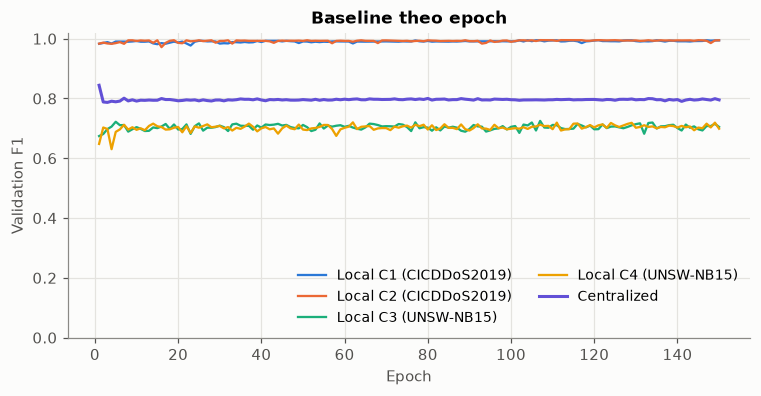

In [6]:
base_dir = RES / RUN_4C / "main" / "das" / "baselines"
base_curves = {}
for f in sorted(base_dir.glob("local_c*_epochs.csv")):
    k = re.match(r"local_c(\d)", f.name).group(1)
    base_curves[f"C{k}"] = pd.read_csv(f)
central = None
if RUN_CENTRAL_4C:
    central = pd.read_csv(next((RES / RUN_CENTRAL_4C / "main" / "das" / "baselines").glob("centralized_*_epochs.csv")))


def plot_baselines(ax):
    for k, e in base_curves.items():
        ax.plot(e["epoch"], e["val_score"], color=COLOR[k], lw=1.5, label=f"Local {k} ({src_of[k]})")
    if central is not None:
        ax.plot(central["epoch"], central["val_score"], color=COLOR["Centralized"], label="Centralized")
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation F1")
    ax.set_title("Baseline theo epoch" + ("" if central is not None else " (chưa có centralized)"))
    ax.legend(ncol=2, loc="lower right", fontsize=9)


fig, ax = plt.subplots(figsize=(8, 3.6))
plot_baselines(ax)
plt.show()

Validation của local-only cao vì mỗi mô hình chỉ được chấm trên **chính nguồn của nó**. Trên tập test của
nguồn còn lại (phần 5), local-only gần như không phát hiện được DoS. Đây là lý do cần FL.

## 5. So sánh trên tập test: 4 client với 2 client

Mỗi checkpoint *best* (chọn theo validation) được chấm **một lần** trên test của cả hai nguồn.
Chỉ số chính là **F1-macro-present**: trung bình F1 trên các lớp thực sự có mặt trong test của nguồn đó.

dataset_id                CICDDoS2019  TB 2 nguồn  UNSW-NB15
pp              cấu hình                                    
Centralized     2 client        0.592       0.608      0.624
                4 client        0.588       0.609      0.630
FL DAS          2 client        0.575       0.557      0.540
                4 client        0.597       0.469      0.341
FL all          2 client        0.625       0.480      0.336
                4 client        0.667       0.507      0.347
FedProx         2 client        0.796       0.692      0.588
                4 client        0.531       0.570      0.609
Local C1 (CIC)  4 client        0.597       0.421      0.244
Local C2 (CIC)  4 client        0.597       0.420      0.243
Local C3 (UNSW) 4 client        0.255       0.466      0.678
Local C4 (UNSW) 4 client        0.205       0.440      0.676
Local CIC       2 client        0.598       0.418      0.239
Local UNSW      2 client        0.131       0.397      0.662

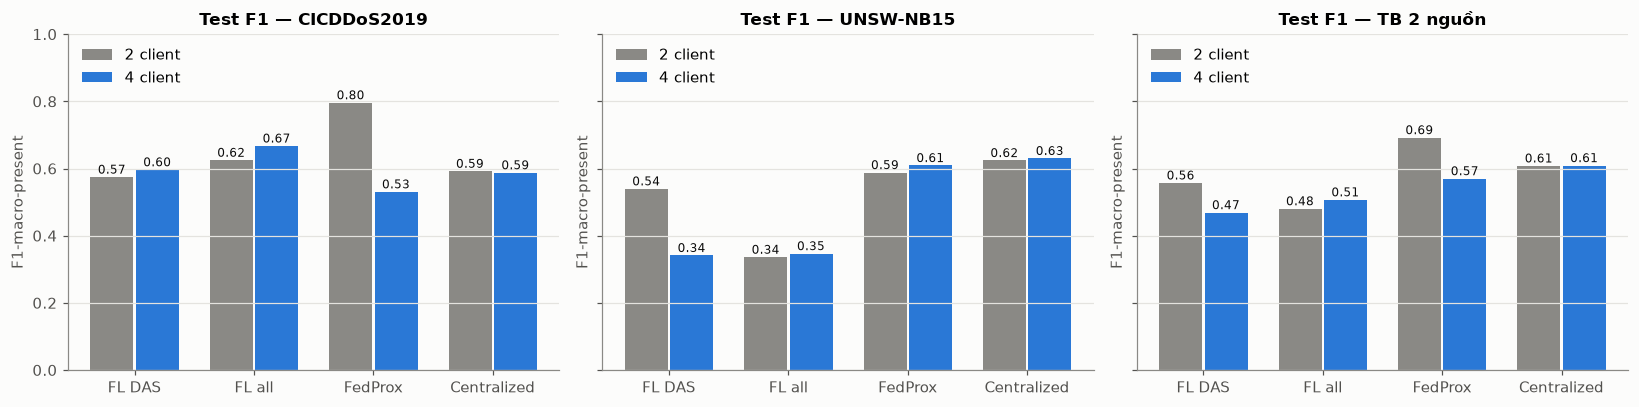

In [7]:
def table(run, variant, tag):
    e = read_eval(run, variant)
    if e.empty:
        return e
    e = e[e.dataset_id.isin(list(SOURCES) + ["mean_over_sources"])].copy()
    e["pp"] = e["method"].map(short)
    e["cấu hình"] = tag
    return e


parts = [table(RUN_4C, "das", "4 client"), table(RUN_4C, "all", "4 client"),
         table(RUN_2C, "das", "2 client"), table(RUN_2C, "all", "2 client"), table(RUN_2C_PROX, "das", "2 client")]
if RUN_CENTRAL_4C:
    parts.append(table(RUN_CENTRAL_4C, "das", "4 client"))
ev = pd.concat([p for p in parts if not p.empty], ignore_index=True)
ev = ev.drop_duplicates(["cấu hình", "pp", "dataset_id"], keep="last")

wide = ev.pivot_table(index=["pp", "cấu hình"], columns="dataset_id", values="f1_macro_present")
wide = wide.rename(columns={**SOURCES, "mean_over_sources": "TB 2 nguồn"}).round(3)
display(wide)

MAIN = ["FL DAS", "FL all", "FedProx", "Centralized"]


def plot_test_compare(ax, col="mean_over_sources", title="Test F1 — TB 2 nguồn"):
    x = np.arange(len(MAIN))
    w = 0.38
    for i, tag in enumerate(["2 client", "4 client"]):
        vals = [ev[(ev.pp == m) & (ev["cấu hình"] == tag) & (ev.dataset_id == col)]["f1_macro_present"]
                for m in MAIN]
        vals = [v.iloc[0] if len(v) else np.nan for v in vals]
        bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.02, color=COLOR[tag], label=tag)
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8,
                        color="#0b0b0b")
            else:
                ax.text(b.get_x() + b.get_width() / 2, 0.03, "chưa có", ha="center", fontsize=8,
                        color="#8a8985")
    ax.set_xticks(x, MAIN)
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1-macro-present")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
plot_test_compare(axes[0], "cicddos2019", "Test F1 — CICDDoS2019")
plot_test_compare(axes[1], "unsw_nb15", "Test F1 — UNSW-NB15")
plot_test_compare(axes[2])
plt.tight_layout()
plt.show()

### Local-only có tổng quát hóa sang nguồn khác không?

In [8]:
loc = ev[ev.pp.str.startswith("Local") & (ev["cấu hình"] == "4 client")]
loc.pivot_table(index="pp", columns="dataset_id", values=["f1_macro_present", "dos_f1"]).round(3)

dos_f1                             f1_macro_present  \
dataset_id      cicddos2019 mean_over_sources unsw_nb15      cicddos2019   
pp                                                                         
Local C1 (CIC)        0.545             0.284     0.023            0.597   
Local C2 (CIC)        0.546             0.282     0.019            0.597   
Local C3 (UNSW)       0.023             0.236     0.450            0.255   
Local C4 (UNSW)       0.000             0.224     0.447            0.205   

                                             
dataset_id      mean_over_sources unsw_nb15  
pp                                           
Local C1 (CIC)              0.421     0.244  
Local C2 (CIC)              0.420     0.243  
Local C3 (UNSW)             0.466     0.678  
Local C4 (UNSW)             0.440     0.676

Mỗi mô hình local chỉ tốt trên nguồn của nó: `dos_f1` trên nguồn còn lại xấp xỉ 0. FL đánh đổi một phần điểm
trên từng nguồn để có một mô hình **dùng được trên cả hai nguồn**.

## 6. Ma trận nhầm lẫn (test)

Chuẩn hóa theo hàng: mỗi hàng là lớp thật, mỗi ô cho biết bao nhiêu phần trăm mẫu bị đoán thành lớp ở cột.
Đường chéo càng đậm thì mô hình càng tốt. Hàng OTHER_ATTACK của CIC trống, vì CIC không có lớp này.

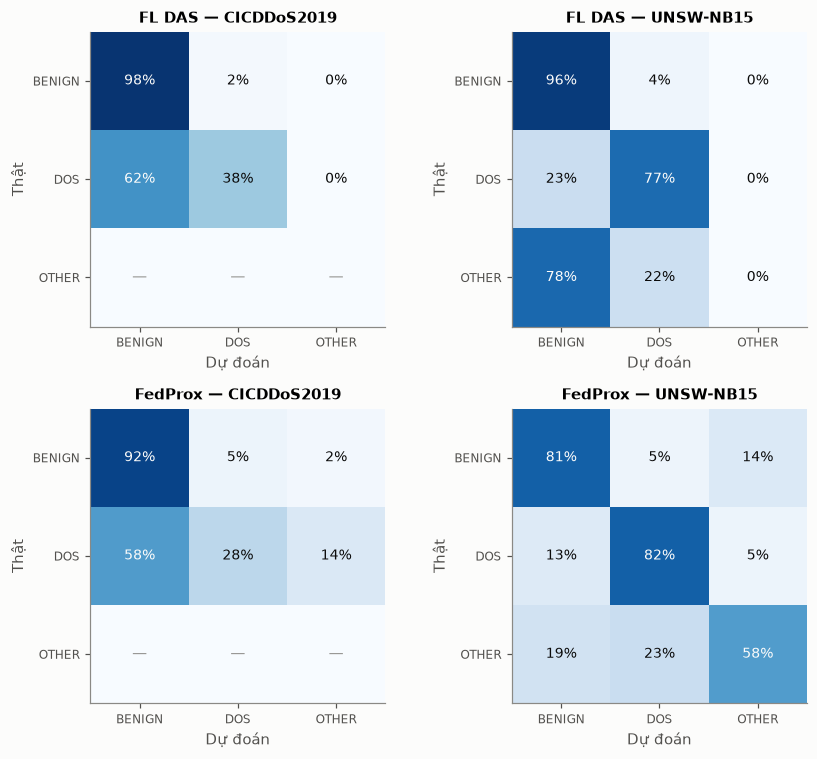

In [9]:
conf = pd.read_csv(RES / RUN_4C / "main" / "das" / "confusion.csv")
conf["pp"] = conf["method"].map(short)


def plot_confusion(ax, method, ds):
    c = conf[(conf.pp == method) & (conf.dataset_id == ds)]
    m = c.pivot_table(index="true", columns="pred", values="n", aggfunc="sum").reindex(
        index=CLASSES, columns=CLASSES, fill_value=0).values.astype(float)
    rows = m.sum(1, keepdims=True)
    p = np.divide(m, rows, out=np.full_like(m, np.nan), where=rows > 0)
    ax.imshow(np.nan_to_num(p), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            if np.isfinite(p[i, j]):
                ax.text(j, i, f"{p[i, j]:.0%}", ha="center", va="center", fontsize=9,
                        color="#fcfcfb" if p[i, j] > 0.55 else "#0b0b0b")
            else:
                ax.text(j, i, "—", ha="center", va="center", color="#8a8985")
    lab = ["BENIGN", "DOS", "OTHER"]
    ax.set_xticks(range(3), lab, fontsize=8)
    ax.set_yticks(range(3), lab, fontsize=8)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thật")
    ax.set_title(f"{method} — {SOURCES[ds]}", fontsize=10)
    ax.grid(False)


fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, method in enumerate(["FL DAS", "FedProx"]):
    for col, ds in enumerate(SOURCES):
        plot_confusion(axes[row, col], method, ds)
plt.tight_layout()
plt.show()

## 7. Dashboard tổng hợp

Gộp các biểu đồ chính vào **một hình duy nhất** để trình bày. Hình được lưu ra
`results_modal_multidataset/dashboard_4_client.png`. Chạy lại ô này sau khi có kết quả centralized
thì dashboard tự cập nhật.

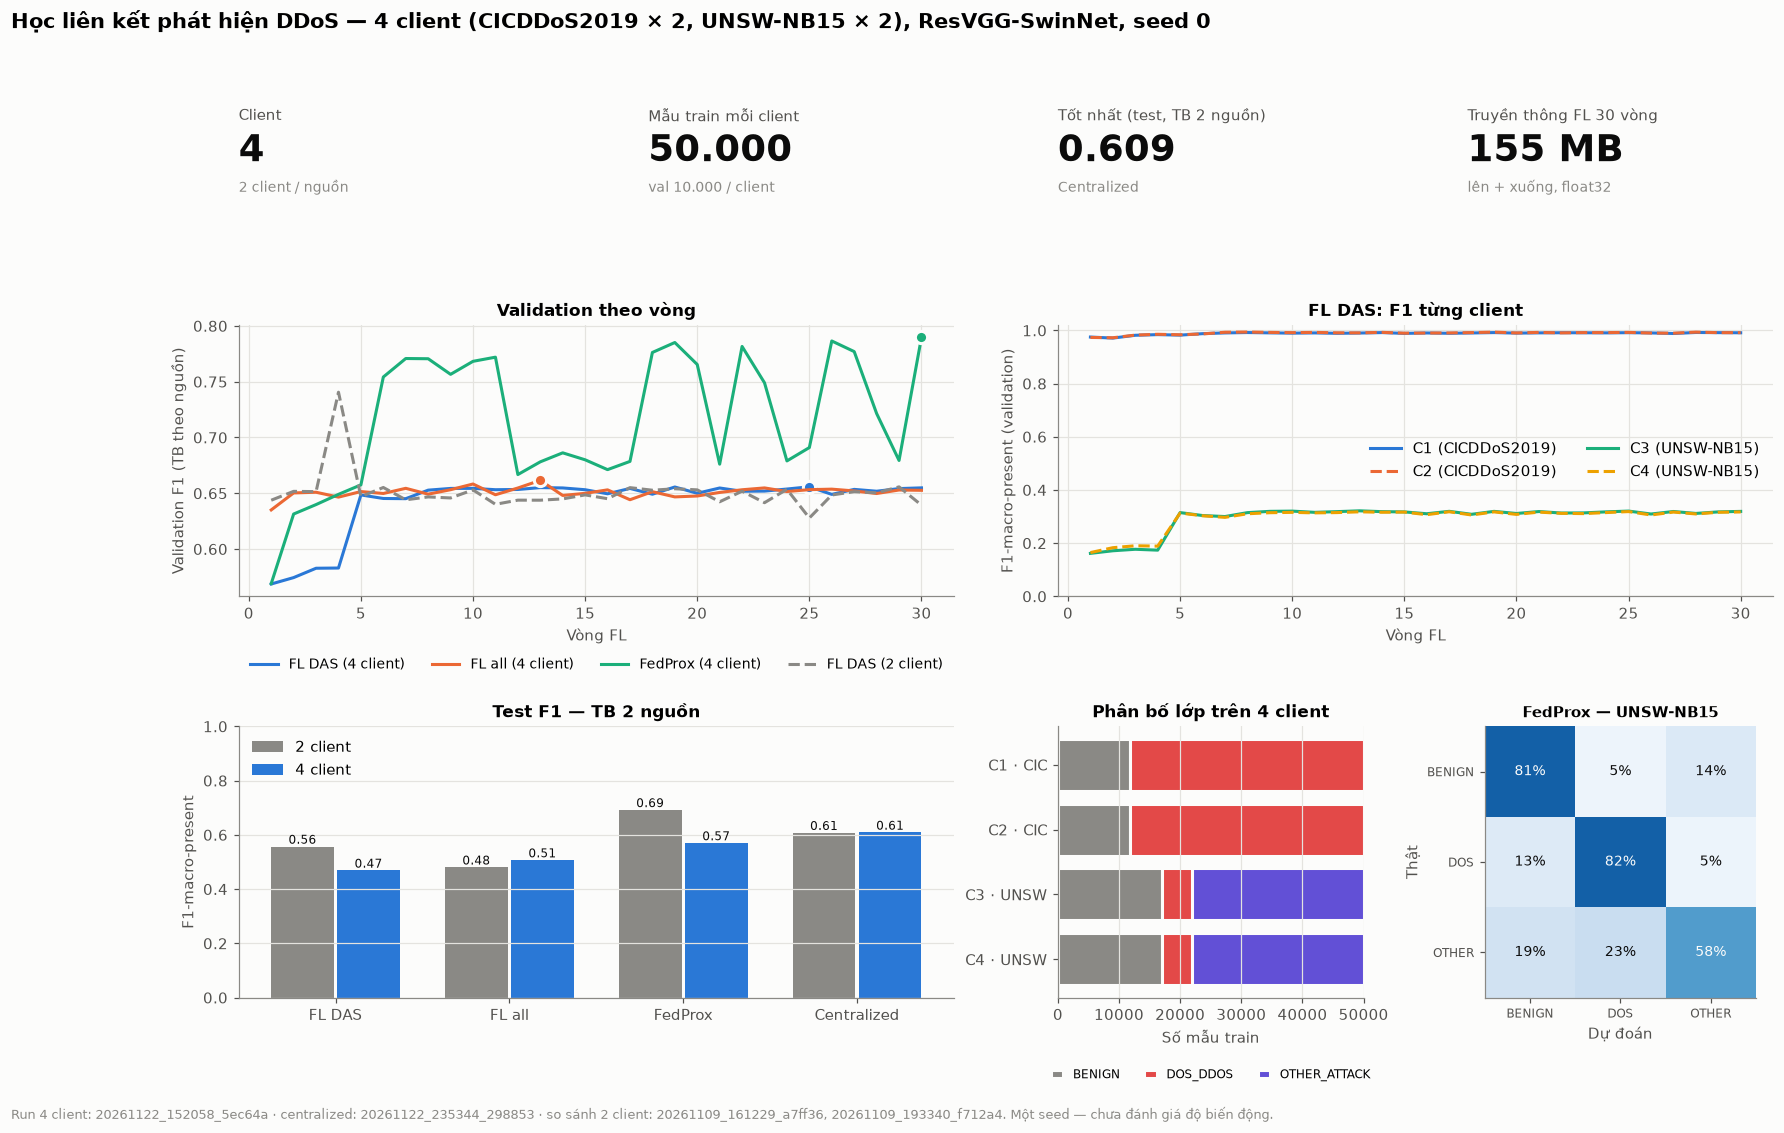

Đã lưu: D:\Work\Learn\HK7_2026-2027\ATTT\Final_Exam\results_modal_multidataset\dashboard_4_client.png


In [10]:
best = ev[(ev["cấu hình"] == "4 client") & (ev.dataset_id == "mean_over_sources") & ev.pp.isin(MAIN)]
best = best.sort_values("f1_macro_present", ascending=False)

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(3, 4, height_ratios=[0.32, 1, 1], hspace=0.62, wspace=0.34)

# Hàng 1: các ô số liệu chính
kpi = [("Client", "4", "2 client / nguồn"),
       ("Mẫu train mỗi client", "50.000", "val 10.000 / client"),
       ("Tốt nhất (test, TB 2 nguồn)", f"{best.f1_macro_present.iloc[0]:.3f}", best.pp.iloc[0]),
       ("Truyền thông FL 30 vòng", f"{curves['FL DAS'].comm_MB.iloc[-1]:.0f} MB", "lên + xuống, float32")]
for i, (title, value, sub) in enumerate(kpi):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.text(0, 1.0, title, fontsize=10, color="#52514e", va="top")
    ax.text(0, 0.5, value, fontsize=24, fontweight="bold", color="#0b0b0b", va="center")
    ax.text(0, 0.0, sub, fontsize=9, color="#8a8985", va="bottom")

plot_fl_val(fig.add_subplot(gs[1, 0:2]))
plot_per_client(fig.add_subplot(gs[1, 2:4]))
plot_test_compare(fig.add_subplot(gs[2, 0:2]))
plot_distribution(fig.add_subplot(gs[2, 2]))
plot_confusion(fig.add_subplot(gs[2, 3]), best.pp.iloc[0] if best.pp.iloc[0] in ("FL DAS", "FedProx") else "FedProx",
               "unsw_nb15")

fig.suptitle("Học liên kết phát hiện DDoS — 4 client (CICDDoS2019 × 2, UNSW-NB15 × 2), ResVGG-SwinNet, seed 0",
             fontsize=14, fontweight="bold", x=0.01, ha="left", y=0.965)
note = (f"Run 4 client: {RUN_4C}" + (f" · centralized: {RUN_CENTRAL_4C}" if RUN_CENTRAL_4C else " · centralized: chưa có") +
        f" · so sánh 2 client: {RUN_2C}, {RUN_2C_PROX}. Một seed — chưa đánh giá độ biến động.")
fig.text(0.01, 0.005, note, fontsize=8.5, color="#8a8985")
out = RES / "dashboard_4_client.png"
fig.savefig(out, bbox_inches="tight", facecolor="#fcfcfb")
plt.show()
print("Đã lưu:", out)

## Bảng số liệu đầy đủ (để đối chiếu)

Mỗi dòng trong bảng truy ngược được về file `evaluation_by_dataset.csv` của run tương ứng.

In [11]:
cols = ["cấu hình", "pp", "dataset_id", "selected_round", "acc", "f1_macro_present", "attack_f1",
        "attack_far_benign", "dos_f1", "attack_roc_auc"]
ev[cols].sort_values(["dataset_id", "pp", "cấu hình"]).round(4).reset_index(drop=True)

,cấu hình,pp,dataset_id,selected_round,acc,f1_macro_present,attack_f1,attack_far_benign,dos_f1,attack_roc_auc
0,2 client,Centralized,cicddos2019,111,0.5950,0.5919,0.5464,0.0258,0.5315,0.8541
1,4 client,Centralized,cicddos2019,1,0.5897,0.5876,0.5421,0.0293,0.5249,0.8660
2,2 client,FL DAS,cicddos2019,4,0.5628,0.5745,0.6177,0.1352,0.5251,0.8244
3,4 client,FL DAS,cicddos2019,25,0.6030,0.5965,0.5454,0.0164,0.5454,0.9064
4,2 client,FL all,cicddos2019,24,0.6286,0.6249,0.5873,0.0175,0.5871,0.8737
5,4 client,FL all,cicddos2019,13,0.6684,0.6672,0.6464,0.0159,0.6466,0.8226
6,2 client,FedProx,cicddos2019,18,0.8032,0.7960,0.8412,0.2687,0.8491,0.8116
7,4 client,FedProx,cicddos2019,30,0.5178,0.5307,0.6160,0.1215,0.3482,0.6953
8,4 client,Local C1 (CIC),cicddos2019,121,0.6036,0.5969,0.5452,0.0134,0.5452,0.8187
9,4 client,Local C2 (CIC),cicddos2019,107,0.6035,0.5970,0.5455,0.0144,0.5455,0.8778
